# Extensions : jusqu'où peut-on aller avec un capteur couleur ?

Suite du benchmark `benchmark_descente_par_couleurs`. Le premier notebook montrait que la descente
par couleurs **coûte plus cher** que la descente exacte ou que Newton quand `f` est connue. Ici on cherche
ce que la couleur apporte **malgré tout** :

| # | Question | Expérience |
|---|---|---|
| 1 | Où converge-t-on depuis chaque point de départ ? | cartes de bassins (couleurs vs exacte vs Newton) |
| 2 | Que se passe-t-il si le capteur est bruité ? | bruit gaussien sur les canaux RGB |
| 3 | Racines multiples : la descente sur `log|f|` bat-elle Newton ? | vitesse de convergence |
| 4 | La **teinte** sert-elle à quelque chose ? | principe de l'argument : compter les zéros avec la seule couleur |
| 5 | Peut-on **trouver tous les zéros** sans point de départ ? | subdivision par enroulement de teinte + raffinement par descente |
| 6 | Que vaut l'invariance d'échelle ? | `f` multipliée par 10^±250 |

**Utilisation** : `Exécution -> Tout exécuter` (environ 4-6 minutes). Les figures sont écrites dans `figures/`
et les chiffres dans `results.json`.


In [1]:
import os, time, math, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb, rgb_to_hsv, ListedColormap
from matplotlib.patches import Rectangle

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
os.makedirs("figures", exist_ok=True)
RES = {}   # résultats chiffrés, exportés en results.json à la fin

def save(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()


## Noyau (repris du premier benchmark)

Encodage couleur, fonctions tests, capteurs, descentes (avec backtracking), harnais, plus un Newton de référence.
Quatre changements : (1) le seuil `|f| > 1e-12` du rendu devient `|f| > 1e-290`, sinon le capteur voyait « noir » dès que `|f|` était minuscule (ce qui contredisait l'invariance d'échelle, voir expérience 6) ; (2) l'écart d'échantillonnage suit le pas (`eps = min(eps, pas/2)`, sinon la différence centrée enjambe le zéro et la descente cycle) ; (3) un **plafond de pas** `step <= 1/|grad ln|f||`, estimation de la distance au zéro obtenue à partir de la seule couleur (`cap=True`) ; (4) le plancher de pas `alpha_min` passe de 1e-4 à 1e-8 (à 1e-4 la descente s'arrêtait vers `|f| ~ 1e-3` alors qu'elle progressait encore). Sans le plafond, la descente rebondit autour du zéro, surtout sur les racines multiples. La cellule suivante mesure son effet.

In [2]:
L0, LAMP, SAT = 0.14, 0.72, 0.85   # plage de luminosite et saturation


def f_to_hsv(F):
    """Valeur(s) complexe(s) -> (h, s, v) : teinte = arg, luminosite = bande de log10|f|."""
    F = np.asarray(F, dtype=complex)
    mod = np.nan_to_num(np.abs(F), nan=0.0, posinf=1e300)
    ok = mod > 1e-290
    hue = (np.angle(F) / (2 * np.pi)) % 1.0
    band = np.where(ok, (np.log10(np.maximum(mod, 1e-300)) % 1.0 + 1.0) % 1.0, 0.0)
    val = np.where(ok, L0 + LAMP * band, 0.05)
    sat = np.where(ok, SAT, 0.0)
    return np.stack([hue, sat, val], axis=-1)


def color_of(F, bits=8):
    """Valeur complexe -> couleur RGB quantifiee (capteur a `bits` bits/canal), floats dans [0,1]."""
    rgb = hsv_to_rgb(np.clip(f_to_hsv(F), 0.0, 1.0))
    if bits >= 16:
        return rgb
    levels = 2 ** bits - 1
    return np.round(rgb * levels) / levels


def decode_t(rgb, ref_t=0.0):
    """Luminosite -> bande de log10|f|, depliee pres de ref_t (leve l'ambiguite x10^k)."""
    v = np.max(rgb, axis=-1)
    band = float(np.clip((v - L0) / LAMP, 0.0, 0.9999))
    return band + float(np.round(ref_t - band))




In [3]:
def make_poly(deg, seed=0):
    """Polynome a racines aleatoires de module dans [0.8, 2.2]."""
    rng = np.random.default_rng(seed)
    roots = rng.uniform(0.8, 2.2, deg) * np.exp(1j * rng.uniform(0, 2 * np.pi, deg))
    coeffs = np.poly(roots)
    return (lambda z: np.polyval(coeffs, z)), list(roots)


F_POLY5, Z_POLY5 = make_poly(5, seed=7)

TESTS = {
    "quad":   dict(f=lambda z: (z - (-1.1 + 0.55j)) * (z - (0.95 - 0.60j)),
                   zeros=[-1.1 + 0.55j, 0.95 - 0.60j],
                   xlim=(-2.5, 2.5), ylim=(-2.5, 2.5)),
    "cubic":  dict(f=lambda z: z**3 - 1,
                   zeros=[np.exp(2j * np.pi * k / 3) for k in range(3)],
                   xlim=(-1.8, 1.8), ylim=(-1.8, 1.8)),
    "expz":   dict(f=lambda z: np.exp(z) - z - 1,
                   zeros=None,  # zeros non listes (metrique |f| seulement)
                   xlim=(-8, 8), ylim=(-8, 8)),
    "poly5":  dict(f=F_POLY5, zeros=Z_POLY5, xlim=(-2.5, 2.5), ylim=(-2.5, 2.5)),
    "double": dict(f=lambda z: (z - 0.8j) ** 2 * (z + 1.3),
                   zeros=[0.8j, 0.8j, -1.3], xlim=(-2.5, 2.5), ylim=(-2.5, 2.5)),
    "sinz":   dict(f=lambda z: np.sin(z) - z,   # zero triple en 0
                   zeros=[0j], xlim=(-6, 6), ylim=(-6, 6)),
}



In [4]:
class ImageSensor:
    """Capteur image : domain coloring rendu une fois, la descente ne lit que des pixels."""

    def __init__(self, f, xlim, ylim, N=300, bits=8):
        self.f, self.N, self.bits = f, N, bits
        self.xlim, self.ylim = xlim, ylim
        self.render_evals = N * N
        xs = np.linspace(xlim[0], xlim[1], N, endpoint=False) + (xlim[1] - xlim[0]) / (2 * N)
        ys = np.linspace(ylim[0], ylim[1], N, endpoint=False) + (ylim[1] - ylim[0]) / (2 * N)
        Z = xs[None, :] + 1j * ys[:, None]
        self.img = color_of(f(Z), bits)

    def read(self, z):
        px = (z.real - self.xlim[0]) / (self.xlim[1] - self.xlim[0]) * self.N - 0.5
        py = (z.imag - self.ylim[0]) / (self.ylim[1] - self.ylim[0]) * self.N - 0.5
        cx = int(np.clip(round(px), 1, self.N - 2))
        cy = int(np.clip(round(py), 1, self.N - 2))
        # pixel le plus proche (pas de moyenne : une moyenne a cheval sur une frontiere de bande
        # melangerait un pixel clair et un pixel sombre et fausserait la luminosite decodee)
        return self.img[cy, cx]

    def show(self, ax):
        ax.imshow(self.img, extent=(*self.xlim, *self.ylim), origin="lower")


class OnDemandSensor:
    """Capteur a la demande : couleur calculee via f au point demande (5 evaluations/iteration)."""

    def __init__(self, f, bits=8):
        self.f, self.bits = f, bits

    def read(self, z):
        return color_of(self.f(np.asarray(z, dtype=complex)), self.bits)


In [5]:
def descend(sensor, z0, alpha=0.12, eps=0.06, maxit=200, tol_log=-3.0,
            alpha_min=1e-8, eps_min=0.0, cap=True):
    """Descente par couleurs : le capteur est la seule source d'information.

    Pas normalise avec backtracking sur la luminosite decodee : si la couleur
    indique que log|f| n'a pas diminue, le pas est divise par 2 (et eps suit le pas).
    Sans cela, un pas fixe oscille a distance ~alpha du zero et n'atteint jamais la tolerance.
    """
    f = sensor.f

    def true_log(z):  # oracle (mesure uniquement, pas utilise pour avancer)
        return np.log10(max(abs(f(np.asarray(z, dtype=complex))), 1e-300))

    z = z0
    traj, logs, status = [z], [true_log(z)], "max"
    last = decode_t(sensor.read(z))
    step = alpha
    margin = 1.5 / (LAMP * (2 ** min(getattr(sensor, 'bits', 8), 12) - 1)) + 3 * getattr(sensor, 'sigma', 0.0) / LAMP  # quantification + bruit capteur
    for _ in range(maxit):
        e = max(eps_min, min(eps, step / 2))
        t0 = decode_t(sensor.read(z), last)
        tE = decode_t(sensor.read(z + e), t0)
        tW = decode_t(sensor.read(z - e), t0)
        tN = decode_t(sensor.read(z + 1j * e), t0)
        tS = decode_t(sensor.read(z - 1j * e), t0)
        last = t0
        gx, gy = (tE - tW) / (2 * e), (tN - tS) / (2 * e)
        gn = math.hypot(gx, gy)
        if gn < 1e-8:
            status = "stall"
            break
        if cap:   # |grad log10|f|| ~ 1/(d ln10) : la couleur donne une estimation de la distance au zero
            step = min(step, 1.0 / (gn * math.log(10)))
        cand = z - step * (gx + 1j * gy) / gn
        if decode_t(sensor.read(cand), t0) > t0 + margin:   # la couleur dit "plus haut" -> pas trop grand
            step /= 2
            if step < alpha_min:
                status = "stall"
                break
            traj.append(z)
            logs.append(logs[-1])
            continue
        z = cand
        step = min(alpha, step * 1.5)
        traj.append(z)
        logs.append(true_log(z))
        if logs[-1] < tol_log:
            status = "ok"
            break
    return np.array(traj), np.array(logs), status


def descend_exact(f, z0, alpha=0.12, maxit=200, tol_log=-3.0, alpha_min=1e-8, cap=True):
    """Descente exacte : direction conj(f'/f), gradient de log|f| (f analytique), meme backtracking."""
    h = 1e-7

    def true_log(z):
        return np.log10(max(abs(f(np.asarray(z, dtype=complex))), 1e-300))

    def df(z):
        return (f(np.asarray(z, dtype=complex) + h) - f(np.asarray(z, dtype=complex) - h)) / (2 * h)

    z = z0
    traj, logs, status = [z], [true_log(z)], "max"
    step = alpha
    for _ in range(maxit):
        w = df(z) / f(np.asarray(z, dtype=complex))
        gn = abs(w)
        if gn < 1e-14:
            status = "stall"
            break
        if cap:
            step = min(step, 1.0 / gn)
        cand = z - step * np.conj(w) / gn
        lc = true_log(cand)
        if lc > logs[-1]:
            step /= 2
            if step < alpha_min:
                status = "stall"
                break
            traj.append(z)
            logs.append(logs[-1])
            continue
        z = cand
        step = min(alpha, step * 1.5)
        traj.append(z)
        logs.append(lc)
        if lc < tol_log:
            status = "ok"
            break
    return np.array(traj), np.array(logs), status




In [6]:
def counted(f):
    """Enveloppe comptant les evaluations de f (scalaires ou tableaux)."""
    def g(z):
        g.n_evals += int(np.size(z))
        return f(z)
    g.n_evals = 0
    return g


def nearest_dist(z, zeros):
    if not zeros:
        return float("nan")
    return float(min(abs(z - r) for r in zeros))


def make_starts(cfg, n=4, margin=0.12):
    """Grille de n x n points de depart interieurs (marge de 12 %)."""
    xs = np.linspace(cfg["xlim"][0] + margin * (cfg["xlim"][1] - cfg["xlim"][0]),
                     cfg["xlim"][1] - margin * (cfg["xlim"][1] - cfg["xlim"][0]), n)
    ys = np.linspace(cfg["ylim"][0] + margin * (cfg["ylim"][1] - cfg["ylim"][0]),
                     cfg["ylim"][1] - margin * (cfg["ylim"][1] - cfg["ylim"][0]), n)
    return [x + 1j * y for x in xs for y in ys]


def run_suite(name, method="couleur", sensor="ondemand", starts=None, sensor_kw=None, **kw):
    """Lance la descente depuis chaque point de depart -> liste de resultats detailles."""
    cfg = TESTS[name]
    params = dict(alpha=0.12, eps=0.06, maxit=200, tol_log=-3.0)
    params.update(kw)   # les parametres balayes (eps, alpha, maxit, tol_log) remplacent les defauts
    starts = make_starts(cfg) if starts is None else starts
    skw = sensor_kw or {}

    sens_img = None
    if method == "couleur" and sensor == "image":
        sens_img = ImageSensor(cfg["f"], cfg["xlim"], cfg["ylim"], **skw)

    rows = []
    for z0 in starts:
        t0 = time.perf_counter()
        if method == "exact":
            fc = counted(cfg["f"])
            p = {k: v for k, v in params.items() if k not in ("eps", "eps_min")}
            traj, logs, status = descend_exact(fc, z0, **p)
            evals = fc.n_evals
        elif sensor == "image":
            traj, logs, status = descend(sens_img, z0, **params)
            evals = 0  # l'image absorbe le cout de rendu (N^2 evaluations, une seule fois)
        else:
            fc = counted(cfg["f"])
            sens = OnDemandSensor(fc, **skw)
            traj, logs, status = descend(sens, z0, **params)
            evals = fc.n_evals
        rows.append(dict(z0=z0, status=status, iters=len(logs) - 1, final_log=logs[-1],
                         dist=nearest_dist(traj[-1], cfg["zeros"]),
                         evals=evals, time=time.perf_counter() - t0))
    return rows


def summarize(rows, fn):
    ok = [r for r in rows if r["status"] == "ok"]
    return dict(fn=fn, n=len(rows), taux=len(ok) / len(rows),
                iters_moy=float(np.mean([r["iters"] for r in ok])) if ok else float("nan"),
                dist_moy=float(np.mean([r["dist"] for r in ok])) if ok else float("nan"),
                evals_moy=float(np.mean([r["evals"] for r in rows])),
                temps_moy=1e3 * float(np.mean([r["time"] for r in rows])))



def newton(f, z0, maxit=200, tol_log=-3.0):
    """Newton complexe (dérivée numérique) : référence."""
    h = 1e-7
    lg = lambda w: np.log10(max(abs(f(np.asarray(w, dtype=complex))), 1e-300))
    z = complex(z0)
    logs, status = [lg(z)], "max"
    for _ in range(maxit):
        fz = f(np.asarray(z, dtype=complex))
        d = (f(np.asarray(z + h, dtype=complex)) - f(np.asarray(z - h, dtype=complex))) / (2 * h)
        if abs(d) < 1e-14 * abs(fz):   # critere relatif (invariant d'echelle)
            status = "stall"; break
        z = z - fz / d
        if (not np.isfinite(z)) or abs(z) > 1e6:
            status = "diverge"; break
        logs.append(lg(z))
        if logs[-1] < tol_log:
            status = "ok"; break
    return z, status, np.array(logs)

def show_dc(ax, cfg, bits=8, N=400):
    xs = np.linspace(*cfg["xlim"], N); ys = np.linspace(*cfg["ylim"], N)
    Z = xs[None, :] + 1j * ys[:, None]
    ax.imshow(color_of(cfg["f"](Z), bits), extent=(*cfg["xlim"], *cfg["ylim"]), origin="lower")
    ax.grid(False)


### Ablation : effet du plafond de pas

Taux de succès (16 départs, capteur à la demande 8 bits, tolérance `log|f| < -3`) avec et sans plafond de pas.


In [7]:
abl = []
for fn in ["quad", "cubic", "poly5", "double", "sinz"]:
    for cap in [False, True]:
        rows = run_suite(fn, sensor="ondemand", cap=cap)
        r = summarize(rows, fn)
        abl.append(dict(fonction=fn, plafond=cap, taux=r["taux"], iters=r["iters_moy"], evals=r["evals_moy"]))
dfa = pd.DataFrame(abl)
RES["ablation"] = abl
print(dfa.round(3).to_string())


  fonction  plafond   taux   iters    evals
0     quad    False  0.938  49.800  397.000
1     quad     True  1.000  31.438  213.000
2    cubic    False  1.000  42.250  280.750
3    cubic     True  1.000  28.875  193.750
4    poly5    False  1.000  59.000  393.125
5    poly5     True  1.000  37.500  252.625
6   double    False  1.000  27.688  188.562
7   double     True  1.000  31.000  210.688
8     sinz    False  1.000  45.500  318.250
9     sinz     True  1.000  44.000  308.750


## Expérience 1 - Bassins d'attraction (convergence globale)

Le premier notebook ne testait que 16 départs. Ici on lance une descente depuis **chaque pixel** d'une grille 36x36 sur
`z^3 - 1` et on colore chaque départ selon la racine atteinte (gris = échec).

**Hypothèse** : les descentes sur `log|f|` donnent des bassins *lisses* (la dynamique suit un gradient),
alors que Newton donne les bassins *fractals* bien connus.


calcul : 35 s


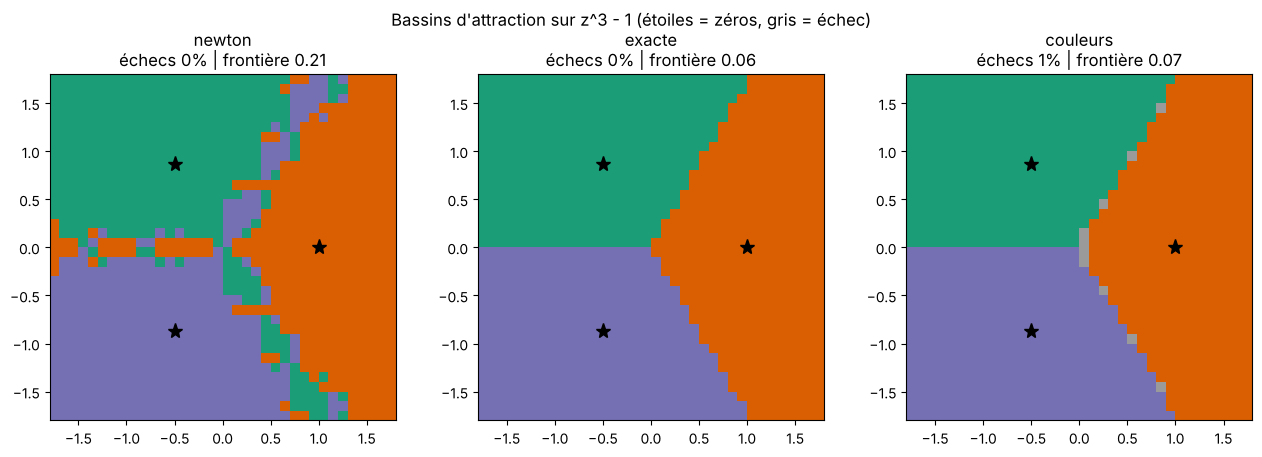

          echec  frontiere
newton    0.000      0.211
exacte    0.000      0.059
couleurs  0.008      0.071


In [8]:
def basin_map(name, method, n=36):
    cfg = TESTS[name]; f = cfg["f"]; zeros = np.array(cfg["zeros"])
    xs = np.linspace(*cfg["xlim"], n); ys = np.linspace(*cfg["ylim"], n)
    lab = -np.ones((n, n), int)
    for iy, y in enumerate(ys):
        for ix, x in enumerate(xs):
            z0 = x + 1j * y
            if method == "newton":
                z, st, _ = newton(f, z0)
            elif method == "exacte":
                traj, _, st = descend_exact(f, z0); z = traj[-1]
            else:
                traj, _, st = descend(OnDemandSensor(f), z0); z = traj[-1]
            if np.isfinite(z) and abs(zeros - z).min() < 0.02:   # converge (precision capteur ~1e-2..1e-3)
                lab[iy, ix] = int(np.argmin(abs(zeros - z)))
    return lab

def boundary_fraction(lab):
    return float((lab[:, 1:] != lab[:, :-1]).mean() + (lab[1:, :] != lab[:-1, :]).mean())

t0 = time.time()
methods = ["newton", "exacte", "couleurs"]
labs = {m: basin_map("cubic", m) for m in methods}
print(f"calcul : {time.time() - t0:.0f} s")

cmap = ListedColormap(["#9a9a9a", "#d95f02", "#1b9e77", "#7570b3"])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
cfg = TESTS["cubic"]
RES["basins"] = {}
for ax, m in zip(axes, methods):
    lab = labs[m]
    ax.imshow(lab + 1, cmap=cmap, vmin=0, vmax=3, extent=(*cfg["xlim"], *cfg["ylim"]), origin="lower")
    for r in cfg["zeros"]:
        ax.plot(r.real, r.imag, "k*", ms=11)
    fail = float((lab < 0).mean()); bnd = boundary_fraction(lab)
    RES["basins"][m] = dict(echec=fail, frontiere=bnd)
    ax.set_title(f"{m}\néchecs {fail:.0%} | frontière {bnd:.2f}")
    ax.grid(False)
fig.suptitle("Bassins d'attraction sur z^3 - 1 (étoiles = zéros, gris = échec)")
plt.tight_layout()
save(fig, "01_bassins")
print(pd.DataFrame(RES["basins"]).T.round(3))


## Expérience 2 - Capteur bruité

Un vrai capteur n'est pas seulement quantifié, il est **bruité**. On ajoute un bruit gaussien d'écart-type `sigma`
(en unités de canal RGB, 1/255 ~ 0,004) à chaque lecture. La descente tolère le bruit de quantification
mais une lecture bruitée peut aussi tromper le test de backtracking.

On distingue deux cas : `sigma` **connu** de la descente (la marge de backtracking s'adapte) ou **inconnu** (marge 8 bits seule).

**Hypothèse** : le succès tient jusqu'à `sigma` ~ quelques 1/255, puis s'effondre ; et connaître `sigma` aide.


calcul : 111 s


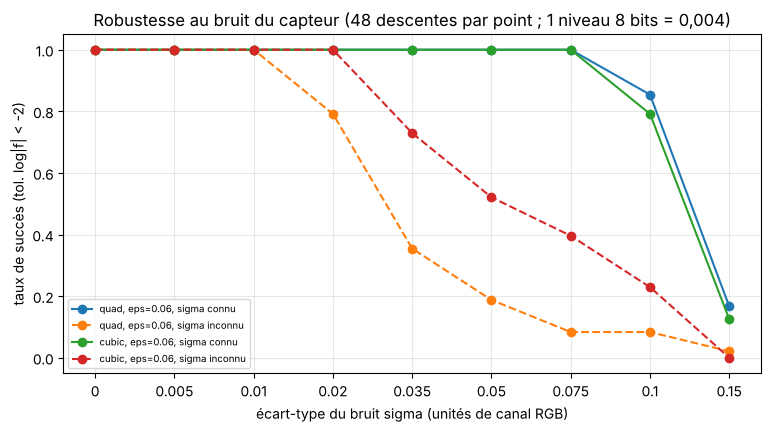

       quad, eps=0.06, sigma connu  quad, eps=0.06, sigma inconnu  \
0.000                         1.00                           1.00   
0.005                         1.00                           1.00   
0.010                         1.00                           1.00   
0.020                         1.00                           0.79   
0.035                         1.00                           0.35   
0.050                         1.00                           0.19   
0.075                         1.00                           0.08   
0.100                         0.85                           0.08   
0.150                         0.17                           0.02   

       cubic, eps=0.06, sigma connu  cubic, eps=0.06, sigma inconnu  
0.000                          1.00                            1.00  
0.005                          1.00                            1.00  
0.010                          1.00                            1.00  
0.020                        

In [9]:
class NoisySensor(OnDemandSensor):
    """Capteur à la demande + bruit gaussien sur les canaux RGB.
    known=True  : le niveau de bruit est connu de la descente (la marge de backtracking en tient compte) ;
    known=False : le niveau de bruit est inconnu (marge de quantification 8 bits seule)."""
    def __init__(self, f, bits=8, sigma=0.0, seed=0, known=True):
        super().__init__(f, bits)
        self.noise = sigma
        self.sigma = sigma if known else 0.0     # lu par descend() pour la marge
        self.rng = np.random.default_rng(seed)
    def read(self, z):
        c = super().read(z)
        return np.clip(c + self.rng.normal(0, self.noise, 3), 0, 1) if self.noise > 0 else c

sigmas = [0, 0.005, 0.01, 0.02, 0.035, 0.05, 0.075, 0.1, 0.15]
configs = [("quad", 0.06, True), ("quad", 0.06, False), ("cubic", 0.06, True), ("cubic", 0.06, False)]
noise = {}
t0 = time.time()
for fn, e, known in configs:
    cfgn = TESTS[fn]; starts = make_starts(cfgn)
    rates = []
    for s in sigmas:
        ok = 0; tot = 0
        for seed in range(3):
            for k, z0 in enumerate(starts):
                sens = NoisySensor(cfgn["f"], bits=8, sigma=s, seed=1000 * seed + k, known=known)
                _, _, st = descend(sens, z0, eps=e, tol_log=-2.0, maxit=300)
                ok += (st == "ok"); tot += 1
        rates.append(ok / tot)
    noise[f"{fn}, eps={e}, sigma {'connu' if known else 'inconnu'}"] = rates
print(f"calcul : {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(9, 4.4))
xs = np.arange(len(sigmas))
for (lab, r), ls in zip(noise.items(), ["-", "--", "-", "--"]):
    ax.plot(xs, r, "o" + ls, label=lab)
ax.set_xticks(xs); ax.set_xticklabels([str(s) for s in sigmas])
ax.set_xlabel("écart-type du bruit sigma (unités de canal RGB)")
ax.set_ylabel("taux de succès (tol. log|f| < -2)")
ax.set_ylim(-0.05, 1.05); ax.legend(fontsize=7)
ax.set_title("Robustesse au bruit du capteur (48 descentes par point ; 1 niveau 8 bits = 0,004)")
save(fig, "02_bruit")
RES["bruit"] = dict(sigmas=sigmas, **noise)
print(pd.DataFrame(noise, index=sigmas).round(2))


## Expérience 3 - Racines multiples : descente sur `log|f|` contre Newton

Newton perd sa convergence quadratique sur une racine multiple (convergence linéaire de raison `1 - 1/m`).
Le gradient de `log|f|`, lui, pointe vers la racine quelle que soit la multiplicité. On compare sur une racine
**double** et une racine **triple**, avec un capteur 12 bits (pour pouvoir descendre jusqu'à `log|f| = -5`).

**Hypothèse** : sur une racine multiple, la descente n'est plus forcément plus lente que Newton en itérations,
mais elle coûte plus d'évaluations ; on regarde les deux.


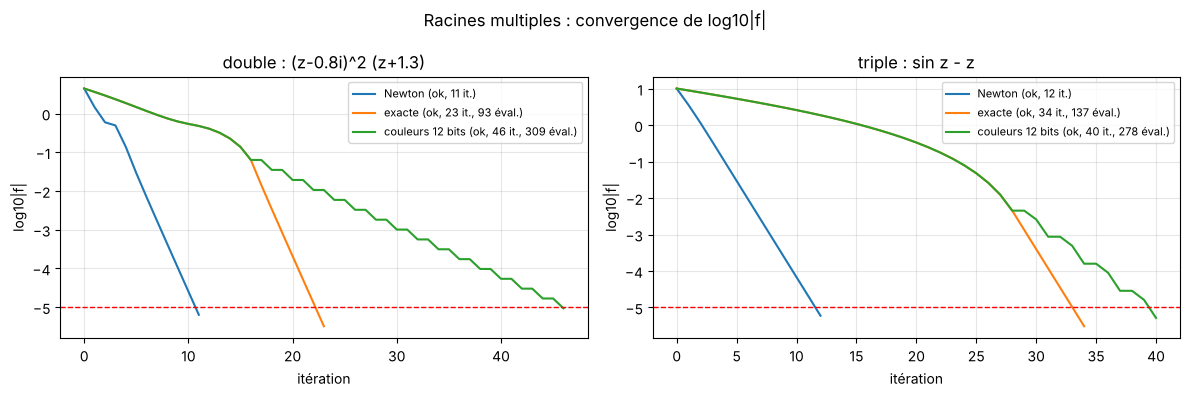

{
 "double": {
  "newton": {
   "status": "ok",
   "iters": 11
  },
  "exacte": {
   "status": "ok",
   "iters": 23,
   "evals": 93
  },
  "couleurs": {
   "status": "ok",
   "iters": 46,
   "evals": 309
  }
 },
 "sinz": {
  "newton": {
   "status": "ok",
   "iters": 12
  },
  "exacte": {
   "status": "ok",
   "iters": 34,
   "evals": 137
  },
  "couleurs": {
   "status": "ok",
   "iters": 40,
   "evals": 278
  }
 }
}


In [10]:
cases = {"double : (z-0.8i)^2 (z+1.3)": ("double", -1.8 + 1.2j),
         "triple : sin z - z": ("sinz", 2.0 + 3.0j)}
mult = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (title, (fn, z0)) in zip(axes, cases.items()):
    f = TESTS[fn]["f"]
    z, st_n, ln = newton(f, z0, maxit=400, tol_log=-5.0)
    fc = counted(f); tr, le, st_e = descend_exact(fc, z0, maxit=400, tol_log=-5.0); ev_e = fc.n_evals
    fc2 = counted(f); tr, lc, st_c = descend(OnDemandSensor(fc2, bits=12), z0, maxit=400, tol_log=-5.0); ev_c = fc2.n_evals
    ax.plot(ln, label=f"Newton ({st_n}, {len(ln)-1} it.)")
    ax.plot(le, label=f"exacte ({st_e}, {len(le)-1} it., {ev_e} éval.)")
    ax.plot(lc, label=f"couleurs 12 bits ({st_c}, {len(lc)-1} it., {ev_c} éval.)")
    ax.axhline(-5, c="r", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("itération"); ax.set_ylabel("log10|f|"); ax.legend(fontsize=8)
    mult[fn] = dict(newton=dict(status=st_n, iters=len(ln) - 1),
                    exacte=dict(status=st_e, iters=len(le) - 1, evals=ev_e),
                    couleurs=dict(status=st_c, iters=len(lc) - 1, evals=ev_c))
fig.suptitle("Racines multiples : convergence de log10|f|")
plt.tight_layout()
save(fig, "03_racines_multiples")
RES["multiples"] = mult
print(json.dumps(mult, indent=1))


## Expérience 4 - La teinte : compter les zéros avec la seule couleur

Jusqu'ici la teinte (`arg f`) n'était pas utilisée. Or le **principe de l'argument** dit que le nombre de zéros
(avec multiplicité) à l'intérieur d'un contour fermé est le nombre de tours que fait `arg f` quand on parcourt ce contour.
Avec un capteur couleur : on lit la teinte en `M` points du contour, on cumule les écarts de teinte (modulo 1) et on divise.

**Hypothèse** : un petit nombre de points suffit tant que la teinte varie de moins d'un demi-tour entre deux points
consécutifs ; la quantification en bits doit peu gêner.


  fonction      centre  rayon  vrai  mesure  arrondi    ok
0     quad  0.00+0.00j    2.0     2     2.0        2  True
1     quad -1.10+0.55j    0.4     1     1.0        1  True
2    cubic  0.00+0.00j    1.4     3     3.0        3  True
3    cubic  1.00+0.00j    0.5     1     1.0        1  True
4    cubic  0.00+0.00j    0.5     0    -0.0        0  True
5    poly5  0.00+0.00j    2.4     5     5.0        5  True
6    poly5  1.17-1.20j    0.3     1     1.0        1  True
7   double  0.00+0.80j    0.3     2     2.0        2  True
8   double  0.00+0.00j    2.0     3     3.0        3  True
9     sinz  0.00+0.00j    1.0     3     3.0        3  True


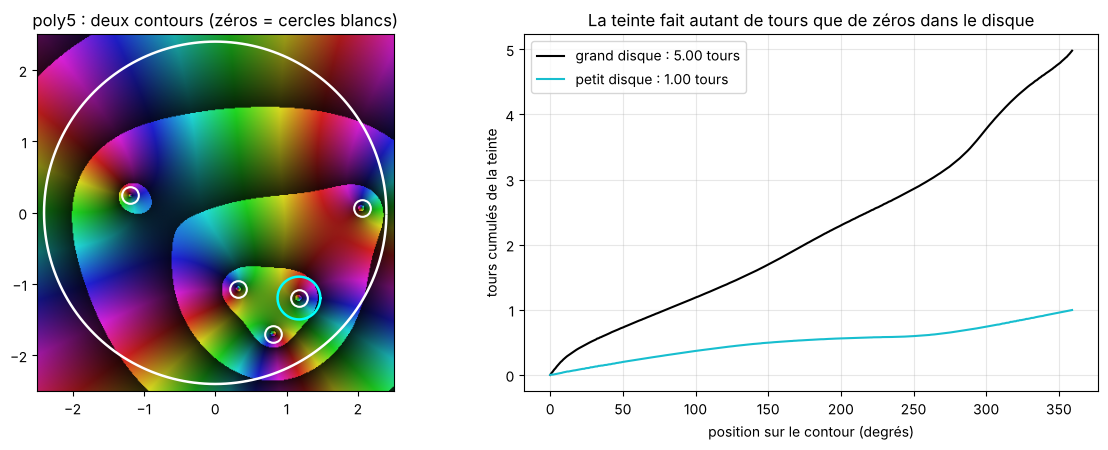

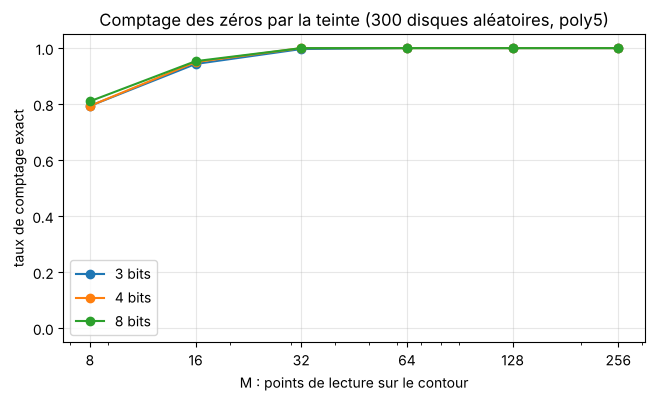

         3      4      8
8    0.793  0.793  0.810
16   0.943  0.950  0.953
32   0.997  1.000  1.000
64   1.000  1.000  1.000
128  1.000  1.000  1.000
256  1.000  1.000  1.000


In [11]:
def winding_from_colors(f, pts, bits=8):
    """Nombre de tours de la teinte le long d'un contour fermé (lue sur la couleur quantifiée)."""
    h = rgb_to_hsv(color_of(f(pts), bits))[:, 0]
    dh = np.diff(np.r_[h, h[0]])
    dh = (dh + 0.5) % 1.0 - 0.5            # écart de teinte ramené dans [-0.5, 0.5[
    return float(dh.sum()), np.cumsum(np.r_[0.0, dh[:-1]])

def circle(c, r, M):
    return c + r * np.exp(2j * np.pi * np.arange(M) / M)

def true_count(fn, c, r):
    zs = TESTS[fn]["zeros"]
    return sum(abs(z - c) < r for z in zs) * (3 if fn == "sinz" else 1)

cases4 = [("quad", 0, 2.0), ("quad", -1.1 + 0.55j, 0.4), ("cubic", 0, 1.4), ("cubic", 1, 0.5),
          ("cubic", 0, 0.5), ("poly5", 0, 2.4), ("poly5", Z_POLY5[0], 0.3),
          ("double", 0.8j, 0.3), ("double", 0, 2.0), ("sinz", 0, 1.0)]
rows = []
for fn, c, r in cases4:
    w, _ = winding_from_colors(TESTS[fn]["f"], circle(c, r, 256), bits=8)
    rows.append(dict(fonction=fn, centre=complex(np.round(c, 2)), rayon=r,
                     vrai=true_count(fn, c, r), mesure=round(w, 3), arrondi=int(round(w))))
df4 = pd.DataFrame(rows)
df4["ok"] = df4.vrai == df4.arrondi
print(df4.to_string())
RES["argument_table"] = dict(accord=int(df4.ok.sum()), total=len(df4))

# --- figure : contour sur poly5 et phase cumulée ---
cfg = TESTS["poly5"]; f = cfg["f"]
big = (0, 2.4); small = (Z_POLY5[0], 0.3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
show_dc(axes[0], cfg)
for (c, r), col in [(big, "white"), (small, "cyan")]:
    p = circle(c, r, 400)
    axes[0].plot(p.real, p.imag, "-", c=col, lw=1.8)
for rz in Z_POLY5:
    axes[0].plot(rz.real, rz.imag, "wo", mfc="none", ms=12, mew=1.5)
axes[0].set_title("poly5 : deux contours (zéros = cercles blancs)")
for (c, r), col, lab in [(big, "k", "grand disque"), (small, "tab:cyan", "petit disque")]:
    w, cum = winding_from_colors(f, circle(c, r, 400))
    axes[1].plot(np.linspace(0, 360, 400, endpoint=False), cum, c=col, label=f"{lab} : {w:.2f} tours")
axes[1].set_xlabel("position sur le contour (degrés)"); axes[1].set_ylabel("tours cumulés de la teinte")
axes[1].legend(); axes[1].set_title("La teinte fait autant de tours que de zéros dans le disque")
plt.tight_layout()
save(fig, "04a_argument_contour")

# --- précision selon M (points par contour) et bits, sur 300 disques aléatoires de poly5 ---
rng = np.random.default_rng(5)
Z5 = np.array(Z_POLY5); discs = []
while len(discs) < 300:
    c = complex(rng.uniform(-2.5, 2.5), rng.uniform(-2.5, 2.5)); r = float(rng.uniform(0.2, 2.0))
    if np.min(abs(abs(Z5 - c) - r)) > 0.05:      # on évite les zéros collés au contour
        discs.append((c, r, int(np.sum(abs(Z5 - c) < r))))
Ms = [8, 16, 32, 64, 128, 256]
acc = {}
for bits in [3, 4, 8]:
    acc[bits] = [float(np.mean([int(round(winding_from_colors(f, circle(c, r, M), bits)[0])) == k
                                for c, r, k in discs])) for M in Ms]
fig, ax = plt.subplots(figsize=(7.5, 4))
for bits, a in acc.items():
    ax.semilogx(Ms, a, "o-", label=f"{bits} bits")
ax.set_xlabel("M : points de lecture sur le contour"); ax.set_ylabel("taux de comptage exact")
ax.set_ylim(-0.05, 1.05); ax.legend(); ax.set_xticks(Ms); ax.set_xticklabels(Ms)
ax.set_title("Comptage des zéros par la teinte (300 disques aléatoires, poly5)")
save(fig, "04b_argument_precision")
RES["argument_precision"] = dict(M=Ms, **{f"{b} bits": a for b, a in acc.items()})
print(pd.DataFrame(acc, index=Ms).round(3))


## Expérience 5 - Trouver *tous* les zéros sans point de départ

On combine les deux idées : la **teinte** dit *combien* de zéros contient un rectangle (enroulement sur son bord),
ce qui permet une subdivision en quadtree qui isole les zéros ; la **luminosité** fait ensuite descendre vers le
zéro depuis le centre de chaque cellule isolée. Tout cela uniquement avec des lectures de couleur.
C'est l'idée de Delves & Lyness (1967) remplacée par un capteur couleur.

**Hypothèse** : on retrouve tous les zéros (racines multiples comprises, avec leur multiplicité) pour
un coût de quelques milliers d'évaluations, sans aucun point de départ.


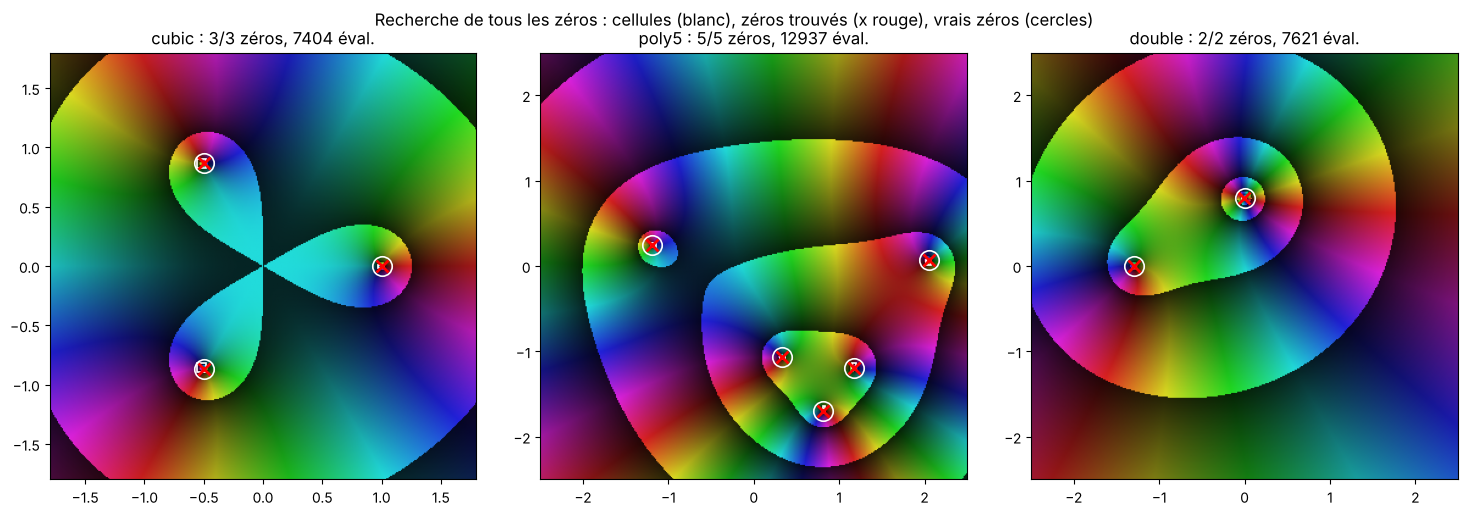

        zeros_vrais  trouves  multiplicite_totale  erreur_max  evals_teinte  \
cubic           3.0      3.0                  3.0      0.0003        7044.0   
poly5           5.0      5.0                  5.0      0.0003       12276.0   
double          2.0      2.0                  3.0      0.0056        7520.0   

        evals_total  
cubic        7404.0  
poly5       12937.0  
double       7621.0  


In [12]:
def count_rect(f, x0, x1, y0, y1, bits=8, max_step=0.02):
    w, h = x1 - x0, y1 - y0
    mx = max(8, int(np.ceil(w / max_step))); my = max(8, int(np.ceil(h / max_step)))
    kx = np.arange(mx) / mx; ky = np.arange(my) / my
    pts = np.concatenate([x0 + kx * w + 1j * y0, x1 + 1j * (y0 + ky * h),
                          (x1 - kx * w) + 1j * y1, x0 + 1j * (y1 - ky * h)])
    return int(round(winding_from_colors(f, pts, bits)[0])), len(pts)

def find_zeros_by_hue(name, min_side=0.1, bits=8):
    cfg = TESTS[name]; fc = counted(cfg["f"])
    (xa, xb), (ya, yb) = cfg["xlim"], cfg["ylim"]
    n0, used = count_rect(fc, xa, xb, ya, yb, bits)
    stack, leaves = [((xa, xb, ya, yb), n0)], []
    while stack:
        (x0, x1, y0, y1), n = stack.pop()
        if n == 0:
            continue
        if max(x1 - x0, y1 - y0) <= min_side:
            leaves.append(((x0, x1, y0, y1), n)); continue
        for frac in (0.4142, 0.5858, 0.3, 0.7):        # coupe décalée : évite un zéro exactement sur la ligne de coupe
            xm, ym = x0 + frac * (x1 - x0), y0 + frac * (y1 - y0)
            kids = [(x0, xm, y0, ym), (xm, x1, y0, ym), (x0, xm, ym, y1), (xm, x1, ym, y1)]
            cnt = []
            for k in kids:
                c, u = count_rect(fc, *k, bits); used += u; cnt.append(c)
            if sum(cnt) == n:
                break
        else:                                         # aucune coupe propre : on garde le parent
            leaves.append(((x0, x1, y0, y1), n)); continue
        stack += [(k, c) for k, c in zip(kids, cnt) if c > 0]
    hue_evals = fc.n_evals
    # raffinement par descente de couleur depuis le centre de chaque feuille
    roots = []
    for (x0, x1, y0, y1), n in leaves:
        z0 = complex((x0 + x1) / 2, (y0 + y1) / 2)
        tr, _, st = descend(OnDemandSensor(fc), z0, alpha=0.04, eps=0.03, maxit=200, tol_log=-3.0)
        roots.append((tr[-1], n))
    merged = []
    for z, n in roots:                         # fusion des doublons (feuilles voisines)
        for m in merged:
            if abs(m[0] - z) < 0.05:
                break
        else:
            merged.append([z, n])
    return cfg, leaves, merged, hue_evals, fc.n_evals

out5 = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, name in zip(axes, ["cubic", "poly5", "double"]):
    cfg, leaves, merged, ev_h, ev_all = find_zeros_by_hue(name)
    show_dc(ax, cfg, N=350)
    for (x0, x1, y0, y1), n in leaves:
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="white", lw=1.2))
    for z, n in merged:
        ax.plot(z.real, z.imag, "rx", ms=9, mew=2)
    tz = sorted(set(np.round(cfg["zeros"], 6)), key=lambda z: (z.real, z.imag))
    for z in tz:
        ax.plot(z.real, z.imag, "wo", mfc="none", ms=14, mew=1.2)
    errs = [min(abs(np.array(tz) - z)) for z, _ in merged]
    out5[name] = dict(zeros_vrais=len(tz), trouves=len(merged), multiplicite_totale=int(sum(n for _, n in merged)),
                      erreur_max=float(max(errs)), evals_teinte=int(ev_h), evals_total=int(ev_all))
    ax.set_title(f"{name} : {len(merged)}/{len(tz)} zéros, {ev_all} éval.")
fig.suptitle("Recherche de tous les zéros : cellules (blanc), zéros trouvés (x rouge), vrais zéros (cercles)")
plt.tight_layout()
save(fig, "05_recherche_zeros")
RES["recherche"] = out5
print(pd.DataFrame(out5).T.round(4))


## Expérience 6 - Invariance d'échelle

On remplace `f` par `s * (z^3 - 1)` avec `s` de 10^-250 à 10^250 (succès = `|f|` divisée par 1000 par rapport à `|s|`).
On compare : la descente par couleurs, la descente exacte (pas normalisé sur `log|f|`), Newton, et une descente de gradient
**classique sur `|f|^2`** à pas fixe, qui n'est pas invariante.

**Attention à l'interprétation** : l'invariance vient de la combinaison *log + pas normalisé*, pas de la couleur en soi.
Ce que la couleur apporte ici est de la **conserver** malgré un capteur 8 bits.


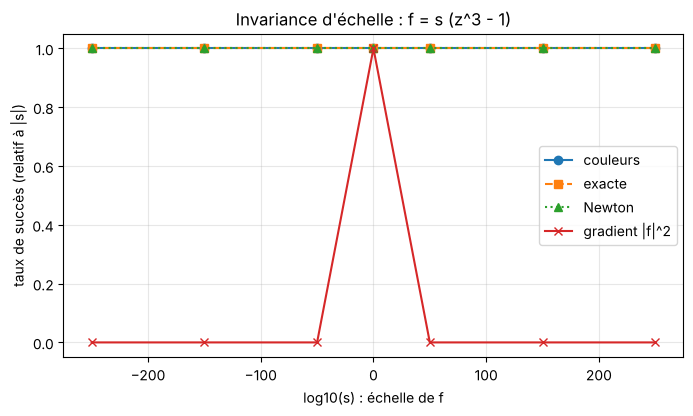

      couleurs  exacte  Newton  gradient |f|^2
-250       1.0     1.0     1.0             0.0
-150       1.0     1.0     1.0             0.0
-50        1.0     1.0     1.0             0.0
 0         1.0     1.0     1.0             1.0
 50        1.0     1.0     1.0             0.0
 150       1.0     1.0     1.0             0.0
 250       1.0     1.0     1.0             0.0


In [13]:
def gd_abs2(s, z0, lr=0.02, maxit=300):
    fs = lambda z: s * (z ** 3 - 1); dfs = lambda z: s * 3 * z ** 2
    z = complex(z0)
    with np.errstate(all="ignore"):
        for _ in range(maxit):
            g = 2 * fs(z) * np.conj(dfs(z))
            z = z - lr * g
            if not np.isfinite(z) or abs(z) > 1e6:
                return False
            if abs(fs(z)) < abs(s) * 1e-3:
                return True
    return False

exps = [-250, -150, -50, 0, 50, 150, 250]
starts = make_starts(TESTS["cubic"])
scale = {m: [] for m in ["couleurs", "exacte", "Newton", "gradient |f|^2"]}
for k in exps:
    s = 10.0 ** k
    fs = lambda z, s=s: s * (z ** 3 - 1)
    tol = k - 3.0
    okc = oke = okn = okg = 0
    for z0 in starts:
        okc += descend(OnDemandSensor(fs), z0, tol_log=tol)[2] == "ok"
        oke += descend_exact(fs, z0, tol_log=tol)[2] == "ok"
        okn += newton(fs, z0, tol_log=tol)[1] == "ok"
        okg += gd_abs2(s, z0)
    n = len(starts)
    for m, v in zip(scale, [okc, oke, okn, okg]):
        scale[m].append(v / n)

fig, ax = plt.subplots(figsize=(8, 4.2))
for (m, r), mk in zip(scale.items(), ["o-", "s--", "^:", "x-"]):
    ax.plot(exps, r, mk, label=m)
ax.set_xlabel("log10(s) : échelle de f"); ax.set_ylabel("taux de succès (relatif à |s|)")
ax.set_ylim(-0.05, 1.05); ax.legend()
ax.set_title("Invariance d'échelle : f = s (z^3 - 1)")
save(fig, "06_echelle")
RES["echelle"] = dict(log10_s=exps, **scale)
print(pd.DataFrame(scale, index=exps).round(2))


## Export des résultats

In [14]:
with open("results.json", "w") as fh:
    json.dump(RES, fh, indent=1, default=float)
print(json.dumps(RES, indent=1, default=float)[:3000])


{
 "ablation": [
  {
   "fonction": "quad",
   "plafond": false,
   "taux": 0.9375,
   "iters": 49.8,
   "evals": 397.0
  },
  {
   "fonction": "quad",
   "plafond": true,
   "taux": 1.0,
   "iters": 31.4375,
   "evals": 213.0
  },
  {
   "fonction": "cubic",
   "plafond": false,
   "taux": 1.0,
   "iters": 42.25,
   "evals": 280.75
  },
  {
   "fonction": "cubic",
   "plafond": true,
   "taux": 1.0,
   "iters": 28.875,
   "evals": 193.75
  },
  {
   "fonction": "poly5",
   "plafond": false,
   "taux": 1.0,
   "iters": 59.0,
   "evals": 393.125
  },
  {
   "fonction": "poly5",
   "plafond": true,
   "taux": 1.0,
   "iters": 37.5,
   "evals": 252.625
  },
  {
   "fonction": "double",
   "plafond": false,
   "taux": 1.0,
   "iters": 27.6875,
   "evals": 188.5625
  },
  {
   "fonction": "double",
   "plafond": true,
   "taux": 1.0,
   "iters": 31.0,
   "evals": 210.6875
  },
  {
   "fonction": "sinz",
   "plafond": false,
   "taux": 1.0,
   "iters": 45.5,
   "evals": 318.25
  },
  {
   "f

## Bilan

Voir `notes/details_exploration.md` pour la lecture commentée des figures. Rappel des limites : fonctions analytiques 2D uniquement,
bruit gaussien indépendant par canal, capteur supposé calibré (la relation luminosité/`log|f|` est connue).
